In [ ]:
import numpy as np
import math
from numpy import linalg as LA
import matplotlib
from matplotlib import pyplot as plt
from pathlib import Path
import sys
import torch

sys.path.append(str(Path.cwd().parent))


from src import KMD_lib

import importlib

importlib.reload(KMD_lib)

from src import KMD_lib
np.random.seed(0)


alpha = 25.0
N = 10000
xL = -1
xU = 1
ss = (xU - xL) / (N - 1)
width = 0.002

t_mesh = np.arange(xL, xU + ss, ss)
t_mesh = t_mesh[:N]

omega_mesh = KMD_lib.make_omega_mesh(t_mesh, alpha)

print(omega_mesh)

T0 = 0.3 / (1 + 0.2 * (t_mesh + 0.5) ** 2)
T1 = (1 / 14) * (1 + 0.2 * (t_mesh + 0.5) ** 2)
T2 = (1 / 20) * (1 + 0.2 * t_mesh + 0.01 * np.abs(t_mesh ** 3))
Freq = np.zeros((3, N))
Freq[0] = 12 * math.pi / T0
Freq[1] = 12 * math.pi / T1
Freq[2] = 12 * math.pi / T2

A0 = 1 + 0.2 * t_mesh ** 2
B0 = -0.5 * 0.2 * t_mesh
A1 = (2 + 0.8 * t_mesh ** 3)
B1 = (2 + 0.8 * t_mesh + 0.5 * t_mesh ** 2)
A2 = (2 + 0.8 * t_mesh)# * np.exp(-(np.maximum(x_mesh_full - 0.25, 0) / 0.05) ** 2)
B2 = (2 - 0.8 * t_mesh ** 3)# * np.exp(-(np.maximum(x_mesh_full - 0.25, 0) / 0.05) ** 2)

Theta = np.zeros((3, N))

for t_indx in range(1, N):
    Theta[0, t_indx] = Theta[0, t_indx - 1] + Freq[0, t_indx - 1] * ss
    Theta[1, t_indx] = Theta[1, t_indx - 1] + Freq[1, t_indx - 1] * ss
    Theta[2, t_indx] = Theta[2, t_indx - 1] + Freq[2, t_indx - 1] * ss

Amp = np.zeros((3, N))
Amp[0] = np.sqrt(A0 ** 2 + B0 ** 2)# * A_vanish
Amp[1] = np.sqrt(A1 ** 2 + B1 ** 2)
Amp[2] = np.sqrt(A2 ** 2 + B2 ** 2)

a2 = np.random.randint(2, size=(7, 2)) * np.random.normal(0, 1, size=(7, 2))
a3 = (1 - np.random.randint(2, size=(7, 2))) * np.random.normal(0, 1, size=(7, 2))

a2[0, 0] = 1.0
a2[0, 1] = 0.0
a3[0, 0] = 1.0
a3[0, 1] = 0.0

a2 = a2 * (1 / ((np.arange(7) + 1.0) ** 2).reshape((-1, 1)))
a3 = a3 * (1 / ((np.arange(7) + 1.0) ** 2).reshape((-1, 1)))

DTheta0 = np.arctan2(-B0, A0)
DTheta1 = np.arctan2(-B1, A1)
DTheta2 = np.arctan2(-B2, A2)

for T_indx in range(N - 1):
    if DTheta0[T_indx + 1] - DTheta0[T_indx] > math.pi:
        DTheta0[T_indx + 1:] -= 2 * math.pi
    if DTheta0[T_indx + 1] - DTheta0[T_indx] < -math.pi:
        DTheta0[T_indx + 1:] += 2 * math.pi

    if DTheta1[T_indx + 1] - DTheta1[T_indx] > math.pi:
        DTheta1[T_indx + 1:] -= 2 * math.pi
    if DTheta1[T_indx + 1] - DTheta1[T_indx] < -math.pi:
        DTheta1[T_indx + 1:] += 2 * math.pi

    if DTheta2[T_indx + 1] - DTheta2[T_indx] > math.pi:
        DTheta2[T_indx + 1:] -= 2 * math.pi
    if DTheta2[T_indx + 1] - DTheta2[T_indx] < -math.pi:
        DTheta2[T_indx + 1:] += 2 * math.pi

Theta[0] += DTheta0
Theta[1] += DTheta1
Theta[2] += DTheta2

signals = np.zeros((3, N))

a = np.zeros((15, 2))
for i in range(8):
    a[2 * i, 0] = (8 / math.pi ** 2) / (2 * i + 1) ** 2

signals0 = Amp[0] * KMD_lib.wave(["custom", a], Theta[0])

signals[0] = Amp[0] * KMD_lib.wave(["tri", 0], Theta[0])
signals[1] = Amp[1] * KMD_lib.wave(["custom", a2], Theta[1])
signals[2] = Amp[2] * KMD_lib.wave(["custom", a3], Theta[2])

signal = np.asarray(signals[0] + signals[1] + signals[2])

Comp_data_full, wp = KMD_lib.semimanual_maxpool_peel2(signal, ["unk", 15], alpha, t_mesh, 0.003, 0.1, ref_fin=True)
wpf = wp.f


N1 = 3333
N2 = 6667
amp1e = Comp_data_full[0, N1:N2, 0]
amp2e = Comp_data_full[1, N1:N2, 0]
amp3e = Comp_data_full[2, N1:N2, 0]
theta1e = Comp_data_full[0, N1:N2, 1]
theta2e = Comp_data_full[1, N1:N2, 1]
theta3e = Comp_data_full[2, N1:N2, 1]
v1e = amp1e * KMD_lib.wave(["custom", wpf[0]], theta1e)
v2e = amp2e * KMD_lib.wave(["custom", wpf[1]], theta2e)
v3e = amp3e * KMD_lib.wave(["custom", wpf[2]], theta3e)

sig1 = signals[0][N1:N2]
sig2 = signals[1][N1:N2]
sig3 = signals[2][N1:N2]
amp1 = Amp[0][N1:N2]
amp2 = Amp[1][N1:N2]
amp3 = Amp[2][N1:N2]

deltheta1 = (Comp_data_full[0, N1:N2, 1] - Theta[0][N1:N2] - math.pi) % (2 * math.pi) - math.pi
deltheta2 = (Comp_data_full[1, N1:N2, 1] - Theta[1][N1:N2] - math.pi) % (2 * math.pi) - math.pi
deltheta3 = (Comp_data_full[2, N1:N2, 1] - Theta[2][N1:N2] - math.pi) % (2 * math.pi) - math.pi

print(LA.norm(v1e - signals0[N1:N2]) / LA.norm(signals0[N1:N2]))
print(LA.norm(v1e - sig1) / LA.norm(sig1))
print(LA.norm(v2e - sig2) / LA.norm(sig2))
print(LA.norm(v3e - sig3) / LA.norm(sig3))

print("XXXXXXXXXXXXXXXXX")

print(np.max(np.abs(v1e - sig1)) / np.max(np.abs(sig1)))
print(np.max(np.abs(v2e - sig2)) / np.max(np.abs(sig2)))
print(np.max(np.abs(v3e - sig3)) / np.max(np.abs(sig3)))
print("XXXXXXXXXXXXXXXXX")


print(LA.norm(amp1e - amp1 * (8 / math.pi ** 2)) / LA.norm(amp1 * (8 / math.pi ** 2)))
print(LA.norm(amp2e - amp2) / LA.norm(amp2))
print(LA.norm(amp3e - amp3) / LA.norm(amp3))
print("XXXXXXXXXXXXXXXXX")


print(((ss / 0.6667) ** 0.5) * LA.norm((Comp_data_full[0, N1:N2, 1] - Theta[0][N1:N2] - math.pi) % (2 * math.pi) - math.pi))
print(((ss / 0.6667) ** 0.5) * LA.norm((Comp_data_full[1, N1:N2, 1] - Theta[1][N1:N2] - math.pi) % (2 * math.pi) - math.pi))
print(((ss / 0.6667) ** 0.5) * LA.norm((Comp_data_full[2, N1:N2, 1] - Theta[2][N1:N2] - math.pi) % (2 * math.pi) - math.pi))

print("XXXXXXXXXXXXXXXXX")

t_mesh1 = np.arange((10000)) * 2 * math.pi / 10000
tri_wave = 1 / (8 / math.pi ** 2) * KMD_lib.wave(["tri", 0], t_mesh1)
a /= 8 / math.pi ** 2
print(LA.norm((tri_wave - KMD_lib.wave(["custom", wpf[0]], t_mesh1))) / LA.norm(tri_wave))
print(LA.norm((KMD_lib.wave(["custom", a], t_mesh1) - KMD_lib.wave(["custom", wpf[0]], t_mesh1))) / LA.norm(KMD_lib.wave(["custom", a], t_mesh1)))
print(LA.norm((KMD_lib.wave(["custom", a2], t_mesh1) - KMD_lib.wave(["custom", wpf[1]], t_mesh1))) / LA.norm(KMD_lib.wave(["custom", a2], t_mesh1)))
print(LA.norm((KMD_lib.wave(["custom", a3], t_mesh1) - KMD_lib.wave(["custom", wpf[2]], t_mesh1))) / LA.norm(KMD_lib.wave(["custom", a3], t_mesh1)))

[  87.42657643   90.50966799   93.70148454   97.00586026  100.42676453
  103.96830673  107.63474115  111.4304721   115.36005921  119.42822292
  123.6398501   128.          132.51391025  137.1870032   142.02489242
  147.03338944  152.21851072  157.58648491  163.1437603   168.89701258
  174.85315286  181.01933598  187.40296908  194.01172051  200.85352906
  207.93661347  215.2694823   222.8609442   230.72011843  238.85644583
  247.2797002   256.          265.0278205   274.37400641  284.04978485
  294.06677888  304.43702144  315.17296982  326.28752059  337.79402516
  349.70630573  362.03867197  374.80593816  388.02344103  401.70705812
  415.87322693  430.53896461  445.72188841  461.44023686  477.71289167
  494.55940041  512.          530.05564101  548.74801282  568.0995697
  588.13355776  608.87404288  630.34593963  652.57504119  675.58805032
  699.41261146  724.07734394  749.61187632  776.04688205  803.41411625
  831.74645387  861.07792922  891.44377682  922.88047371  955.42578333
  989.1

In [25]:
Comp_data_full.shape

(3, 10000, 4)

In [62]:
def make_waveform_fn(coeffs):
    coeffs = torch.as_tensor(coeffs)

    def y(x):
        x = torch.as_tensor(x, dtype=coeffs.dtype, device=coeffs.device)
        out = torch.zeros_like(x)

        for k in range(coeffs.shape[0]):
            n = k + 1
            out = out + coeffs[k, 0] * torch.cos(n * x)
            if k > 0:
                out = out + coeffs[k, 1] * torch.sin(n * x)
        return out

    return y

In [63]:
def make_one_step_data(x, L=3):
    X, y = [], []
    for i in range(len(x) - L):
        X.append(x[i:i+L])
        y.append(x[i+L])
    return torch.stack(X), torch.stack(y)

def pairwise_sqdist(X1, X2):
    x1_norm = (X1**2).sum(dim=1, keepdim=True)
    x2_norm = (X2**2).sum(dim=1, keepdim=True).T
    return x1_norm + x2_norm - 2 * (X1 @ X2.T)

def gaussian_gram(X1, X2, ell):
    D2 = pairwise_sqdist(X1, X2)
    return torch.exp(-D2 / (2 * ell**2))

def median_lengthscale(X, max_points=2000):
    if len(X) > max_points:
        idx = torch.randperm(len(X))[:max_points]
        Xs = X[idx]
    else:
        Xs = X
    D2 = pairwise_sqdist(Xs, Xs)
    D = torch.sqrt(torch.clamp(D2, min=0.0))
    vals = D[torch.triu(torch.ones_like(D, dtype=torch.bool), diagonal=1)]
    vals = vals[vals > 0]
    if len(vals) == 0:
        return 1.0
    return torch.median(vals).item()

class KernelRepresenterForecaster:
    def __init__(self, L=3, ell=None, lam=1e-4, standardize=True):
        self.L = L
        self.ell = ell
        self.lam = lam
        self.standardize = standardize

        self.x_mean = None
        self.x_std = None
        self.X_train = None
        self.alpha = None

    def fit(self, x):
        X_train, y_train = make_one_step_data(x, L=self.L)

        if self.standardize:
            self.x_mean = x.mean()
            self.x_std = x.std()
            if self.x_std < 1e-8:
                self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)
            X_train = (X_train - self.x_mean) / self.x_std
            y_train = (y_train - self.x_mean) / self.x_std
        else:
            self.x_mean = torch.tensor(0.0, dtype=x.dtype, device=x.device)
            self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)

        if self.ell is None:
            self.ell = median_lengthscale(X_train)

        K = gaussian_gram(X_train, X_train, self.ell)
        n = len(X_train)
        K_reg = K + self.lam * torch.eye(n, dtype=K.dtype, device=K.device)

        self.X_train = X_train
        self.alpha = torch.linalg.solve(K_reg, y_train)

    def predict_next(self, x_window):
        xq = x_window.clone()
        if self.standardize:
            xq = (xq - self.x_mean) / self.x_std

        kq = gaussian_gram(xq.unsqueeze(0), self.X_train, self.ell).squeeze(0)
        yq = torch.dot(kq, self.alpha)

        if self.standardize:
            yq = yq * self.x_std + self.x_mean
        return yq

    def recursive_forecast(self, x_history, horizon_steps):
        history = x_history.clone()
        preds = []
        for _ in range(horizon_steps):
            x_window = history[-self.L:] 
            y_next = self.predict_next(x_window)
            preds.append(y_next)
            history = torch.cat([history, y_next.view(1)])
        return torch.stack(preds)

In [64]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def rmse(pred, true):
    return torch.sqrt(torch.mean((pred - true)**2))

def mae(pred, true):
    return torch.mean(torch.abs(pred - true))

v = torch.Tensor(signal)
n = len(v)
n_train = int(0.7 * n)

v_train, v_test = v[:n_train], v[n_train:]

full_data = torch.Tensor(Comp_data_full)

a1_train, a1_test = full_data[0,:n_train,0], full_data[0,n_train:,0]
a2_train, a2_test = full_data[1,:n_train,0], full_data[1,n_train:,0]
a3_train, a3_test = full_data[2,:n_train,0], full_data[2,n_train:,0]

theta1_train, theta1_test = full_data[0,:n_train,1], full_data[0,n_train:,1]
theta2_train, theta2_test = full_data[1,:n_train,1], full_data[1,n_train:,1]
theta3_train, theta3_test = full_data[2,:n_train,1], full_data[2,n_train:,1]

omega1_train, omega1_test = full_data[0,:n_train,2], full_data[0,n_train:,2]
omega2_train, omega2_test = full_data[1,:n_train,2], full_data[1,n_train:,2]
omega3_train, omega3_test = full_data[2,:n_train,2], full_data[2,n_train:,2]

v_train, v_test = v[:n_train], v[n_train:]

L_a = 1000
L_omega = 500
H = 50


In [65]:
def rmse(x, y):
    return torch.sqrt(torch.mean((x - y)**2))

L = 1000
horizon_steps = len(v[n_train:])

model_v = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_v.fit(v_train)
pred_from_v = model_v.recursive_forecast(v_train, horizon_steps)


model_a1 = KernelRepresenterForecaster(L=L_a, ell=None, lam=1e-4, standardize=True)
model_a2 = KernelRepresenterForecaster(L=L_a, ell=None, lam=1e-4, standardize=True)
model_a3 = KernelRepresenterForecaster(L=L_a, ell=None, lam=1e-4, standardize=True)

model_a1.fit(a1_train)
model_a2.fit(a2_train)
model_a3.fit(a3_train)

a1_pred = model_a1.recursive_forecast(a1_train, horizon_steps)
a2_pred = model_a2.recursive_forecast(a2_train, horizon_steps)
a3_pred = model_a3.recursive_forecast(a3_train, horizon_steps)


# 3) use true v1, v2 separately and sum
model_omega1 = KernelRepresenterForecaster(L=L_omega, ell=None, lam=1e-4, standardize=True)
model_omega2 = KernelRepresenterForecaster(L=L_omega, ell=None, lam=1e-4, standardize=True)
model_omega3 = KernelRepresenterForecaster(L=L_omega, ell=None, lam=1e-4, standardize=True)

model_omega1.fit(omega1_train)
model_omega2.fit(omega2_train)
model_omega3.fit(omega3_train)

omega1_pred = model_omega1.recursive_forecast(omega1_train, horizon_steps)
omega2_pred = model_omega2.recursive_forecast(omega2_train, horizon_steps)
omega3_pred = model_omega3.recursive_forecast(omega3_train, horizon_steps)

theta1_pred = torch.zeros(horizon_steps)
theta2_pred = torch.zeros(horizon_steps)
theta3_pred = torch.zeros(horizon_steps)

theta1_pred[0] = theta1_train[-1]+ss*omega1_train[-1]
theta2_pred[0] = theta2_train[-1]+ss*omega2_train[-1]
theta3_pred[0] = theta3_train[-1]+ss*omega3_train[-1]

for i in range(1,horizon_steps):
    theta1_pred[i] = theta1_pred[i-1]+ss*omega1_pred[i-1]
    theta2_pred[i] = theta2_pred[i-1]+ss*omega2_pred[i-1]
    theta3_pred[i] = theta3_pred[i-1]+ss*omega3_pred[i-1]





In [74]:
y1 = make_waveform_fn(wp.f[0])
y2 = make_waveform_fn(wp.f[1])
y3 = make_waveform_fn(wp.f[2])

osc_1 = y1(theta1_pred)
osc_2 = y2(theta2_pred)
osc_3 = y3(theta3_pred)

pred_from_KMD = a1_pred*osc_1+a2_pred*osc_2+a3_pred*osc_3

h = 500

err_v = torch.linalg.norm(pred_from_v[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])
err_kmd = torch.linalg.norm(pred_from_KMD[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])

print("Relative error: using v directly, scored vs future v =", err_v.item())
print(r"Relative error: using predicted $a_i,\omega_i$, scored vs future v =", err_kmd.item())

Relative error: using v directly, scored vs future v = 1.1538783311843872
Relative error: using predicted $a_i,\omega_i$, scored vs future v = 0.1123084064659849


In [75]:
om_mesh = KMD_lib.make_omega_mesh(t_mesh, alpha)

E_original = KMD_lib.compute_E_fast(
    t_mesh,
    om_mesh,
    wp,
    signal,
    np.zeros((0, len(t_mesh), 4)),
    np.zeros((0, len(t_mesh), 2, 2)),
    0,
    alpha
)

Energy computation progress:
0% 32 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
4% 32 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
9% 16 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
13% 16 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
17% 16 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
21% 16 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
26% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=18, tm_min=39, tm_sec=10, tm_wday=0, tm_yday=103, tm_isdst=1)
30% 8 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hou

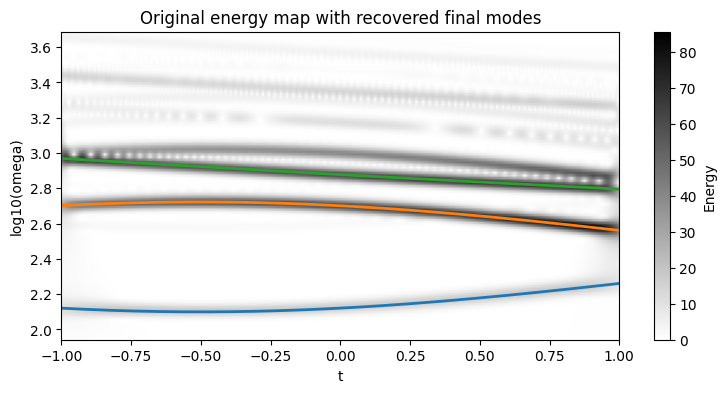

In [76]:
plt.figure(figsize=(9, 4))
plt.imshow(
    E_original,
    cmap="gray_r",
    origin="lower",
    aspect="auto",
    extent=[t_mesh[0], t_mesh[-1], np.log10(om_mesh[0]), np.log10(om_mesh[-1])]
)

for mode_i in range(Comp_data_full.shape[0]):
    omega_i = Comp_data_full[mode_i, :, 2]
    nz = np.nonzero(omega_i)[0]
    if len(nz) > 0:
        plt.plot(t_mesh[nz], np.log10(omega_i[nz]), linewidth=2)

plt.colorbar(label="Energy")
plt.xlabel("t")
plt.ylabel("log10(omega)")
plt.title("Original energy map with recovered final modes")
plt.show()

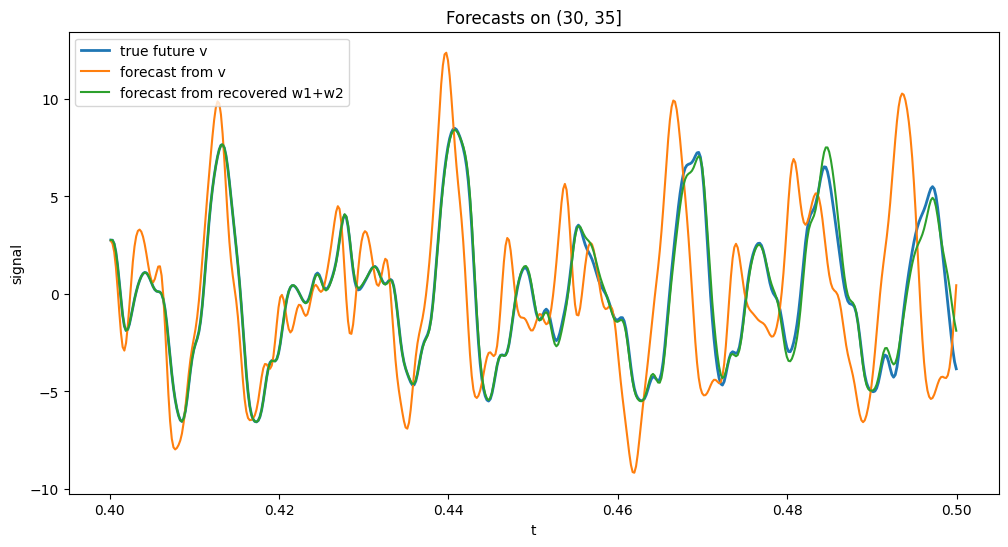

In [72]:
t_future = t_mesh[n_train:]
plt.figure(figsize=(12, 6))
plt.plot(t_future[:h], v_test[:h], label="true future v", linewidth=2)
plt.plot(t_future[:h], pred_from_v[:h], label="forecast from v")
plt.plot(t_future[:h], pred_from_KMD[:h], label="forecast from recovered w1+w2")
plt.legend()
plt.xlabel("t")
plt.ylabel("signal")
plt.title("Forecasts on (30, 35]")
plt.show()